# **Taller 1:  Regresión**

En este taller la idea es reforzar los conocimientos en los temas de regresión lineal.

# **1. Regresión lineal**

Para ello vamos a trabajar con  la data numérica del  archivo **data.csv**

In [184]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # statistical data visualization
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


### **Manejo de datos:**

1. Leer el archivo ```data.csv``` y verificar que no tenga valores nulos, mostrar su cantidad de filas y columnas, tipos de datos e imprimir los 5 primeros registros.

In [185]:
dataFrame= pd.read_csv('data.csv')
dataFrame

,Duration,Pulse,Maxpulse,Calories
0,60,110,130,409.1
1,60,117,145,479.0
2,60,103,135,340.0
3,45,109,175,282.4
4,45,117,148,406.0
...,...,...,...,...
164,60,105,140,290.8
165,60,110,145,300.0
166,60,115,145,310.2
167,75,120,150,320.4


In [186]:
print(dataFrame.isnull().sum())   # total de NaN en todo el dataset

Duration    0
Pulse       0
Maxpulse    0
Calories    5
dtype: int64


In [187]:
dataFrame = dataFrame.dropna(subset=['Calories'])## eliminar filas con NaN en Calories, como son pocas filas no afecta el análisis
print(dataFrame.isnull().sum())   

Duration    0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64


**Nota:** existe nulos en la variable Calories

2. Separando la información: <br>
    2.1 Separar los datos en Input (X) y Output (y), para el Input seleccionar las columnas ```Pulse``` y  ```Maxpulse```. <br>
    2.2 Separar los datos en Train y Test, dejar 80% de datos para entrenamiento

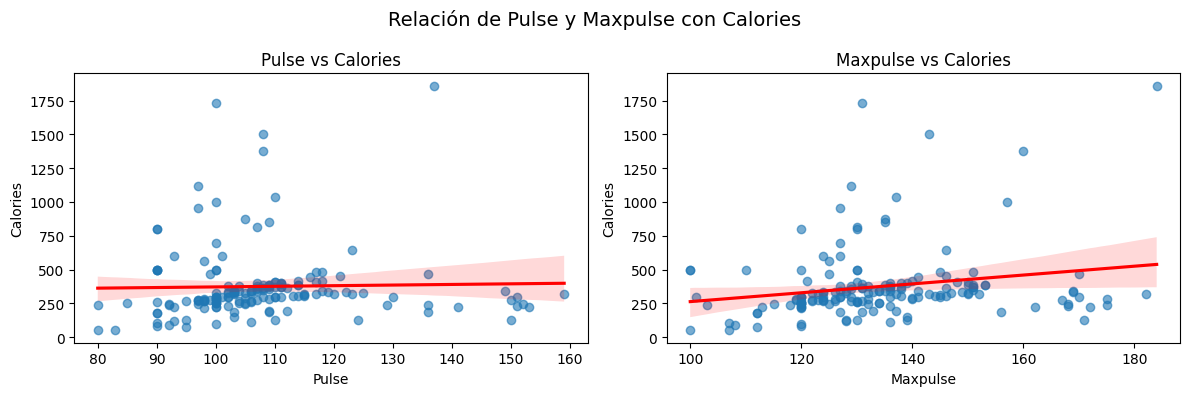

In [188]:
X = dataFrame[['Pulse', 'Maxpulse']] # Input features
y = dataFrame[['Calories']]# Output variable


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# gráficas de dispersión con línea de regresión
features = ['Pulse', 'Maxpulse']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, features):
    sns.regplot(
        data=dataFrame, 
        x=col, 
        y="Calories", 
        ax=ax, 
        scatter_kws={"alpha":0.6}, 
        line_kws={"color":"red"}
    )
    ax.set_title(f"{col} vs Calories")

plt.suptitle("Relación de Pulse y Maxpulse con Calories", fontsize=14)
plt.tight_layout()
plt.show()

**Nota:** Se evidencia que existe ruido en ambas graficas, pero que a mayor Maxpulse, tiende a aumentar Calories, en cambio en Pulse es casi plana. No seria viable con los datos relacionados a los inputs. Se reaiza sacar como. Input a Pulse y predecir Maxpulse.

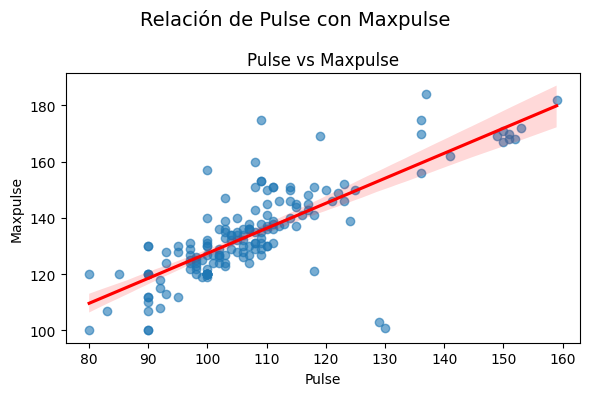

In [189]:
X = dataFrame[['Pulse']] # Input features
y = dataFrame[['Maxpulse']]# Output variable


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# gráficas de dispersión con línea de regresión
fig, ax = plt.subplots(figsize=(6, 4))

sns.regplot(
    data=dataFrame, 
    x="Pulse", 
    y="Maxpulse", 
    ax=ax, 
    scatter_kws={"alpha":0.6}, 
    line_kws={"color":"red"}
)

ax.set_title("Pulse vs Maxpulse")
plt.suptitle("Relación de Pulse con Maxpulse", fontsize=14)
plt.tight_layout()
plt.show()

### **Creando un modelo de regresión lineal:**

3. Crear un modelo de regresión lineal simple y entrenarlo.

In [190]:
# Crear y entrenar el modelo de regresión lineal
print(X_train.shape, y_train.shape)

linear_reg = LinearRegression()
linear_reg.fit(X_train, y_train)

(131, 1) (131, 1)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


4. Obtener los coeficientes $\theta_{0}$  y $\theta_{}1$ de  la recta de ajuste., tal que  $y=\theta_{1}x +\theta_{0}$  y el error cuadrático.

In [191]:


print('Coeficiente (pendiente):', linear_reg.coef_)
print('Intercepto:', linear_reg.intercept_)


Coeficiente (pendiente): [[0.86219031]]
Intercepto: [41.5242089]


In [192]:
y_pred = linear_reg.predict(X_test) # hacer predicciones

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
RMSE=np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Error cuadrático medio (MSE): {mse:.2f}")
print(f"Coeficiente de determinación (R²): {r2:.2f}")

target = y.values.flatten()  
y_min, y_max, y_mean, y_std = np.min(target), np.max(target), np.mean(target), np.std(target)
print(f"RMSE = {RMSE:.2f}")
print(f"Comparación del RMSE con la media de predicciones = {(RMSE/(y_mean))*100:.2f}%")


Error cuadrático medio (MSE): 59.64
Coeficiente de determinación (R²): 0.83
RMSE = 7.72
Comparación del RMSE con la media de predicciones = 5.75%


**Nota** es un modelo funcional, tiene muy pocos errores de predición.

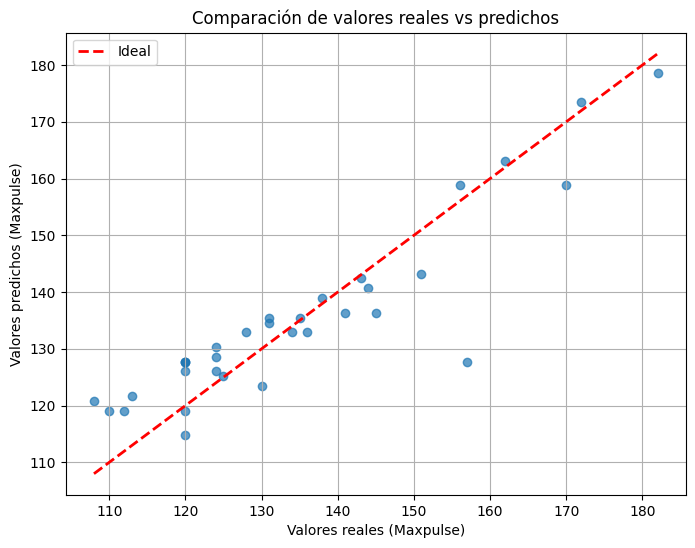

In [193]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal')
plt.xlabel('Valores reales (Maxpulse)')
plt.ylabel('Valores predichos (Maxpulse)')
plt.title('Comparación de valores reales vs predichos')
plt.legend()
plt.grid(True)
plt.show()

**Nota:** el modelo sí está aprendiendo la relación entre Pulse y Maxpulse y tiene un buen ajuste.

# **2. CLASIFICACIÓN Y REGRESIÓN LOGÍSTICA**

En esta parte del taller se trabajan los temas de regresión logística como un  clasificador binario y la clasificación binaria usando SVMs.

### **REGRESIÓN LOGÍSTICA**
Para una compañía que ofrece un producto o servicio es muy importante llegar a la mayor cantidad de gente posible mediante la publicidad por distintos medios como internet. Existen medios, como las redes sociales, en los que las empresas pagan para publicitarse mediante estos servicios, así, muchas empresas llegan a varias personas con el fin de llamar su atención.

Muchos medios como Google o Facebook realizan reportes para las personas que se publicitan, suministrando información como la cantidad de personas que vieron la publicidad, quienes se interesaron en la misma, y demás información de las personas que interactuaron con esta. Con esta información las empresas pueden trabajar en mejorar su publicidad para llegar a un público mayor o más afin con sus productos, realizando predicciones sobre que personas se interesarán en una publicidad.

Nuestro trabajo es intentar predecir si una persona se interesará en una publicidad en línea, haciendo click en ella. Para realizar las predicciones nos basaremos en la información de las personas suministrada por la plataforma mediante la cual se realiza la publicidad.

### **Los datos:**
Contamos con un conjunto de datos con información de varios posibles clientes que recibieron la publicidad, a continuación se presentan las columnas más relevantes para realizar el trabajo:
- **Daily Time Spent on Site:** tiempo que estuvo el cliente dentro de la página web (minutos)
- **Age:** edad del cliente (años)
- **Area Income:** Ingreso promedio de las personas ubicadas en la región geográfica del cliente
- **Daily Internet Usage:** Tiempo promedio de uso de internet del cliente al día (minutos)
- **Male:** Si el cliente es de sexo masculino
- **Clicked on Ad:** Si el cliente hizo click en la publicidad (1/0 para Sí/No)

---

### **Manejo de datos:**

5. Leer el archivo ```advertising.csv``` y verificar que no tenga valores nulos, mostrar su cantidad de filas y columnas, tipos de datos e imprimir los 5 primeros registros.

In [194]:
dataFrame2 = pd.read_csv('advertising.csv')
dataFrame2

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0
...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,Fundamental modular algorithm,Duffystad,1,Lebanon,2016-02-11 21:49:00,1
996,51.30,45,67782.17,134.42,Grass-roots cohesive monitoring,New Darlene,1,Bosnia and Herzegovina,2016-04-22 02:07:01,1
997,51.63,51,42415.72,120.37,Expanded intangible solution,South Jessica,1,Mongolia,2016-02-01 17:24:57,1
998,55.55,19,41920.79,187.95,Proactive bandwidth-monitored policy,West Steven,0,Guatemala,2016-03-24 02:35:54,0


In [195]:
# Verificar valores nulos
print(dataFrame2.isnull().sum())

# Mostrar cantidad de filas y columnas
print(f"Filas: {dataFrame2.shape[0]}, Columnas: {dataFrame2.shape[1]}")

# Mostrar tipos de datos
print(dataFrame2.dtypes)

# Imprimir los 5 primeros registros
print(dataFrame2.head())

Daily Time Spent on Site    0
Age                         0
Area Income                 0
Daily Internet Usage        0
Ad Topic Line               0
City                        0
Male                        0
Country                     0
Timestamp                   0
Clicked on Ad               0
dtype: int64
Filas: 1000, Columnas: 10
Daily Time Spent on Site    float64
Age                           int64
Area Income                 float64
Daily Internet Usage        float64
Ad Topic Line                object
City                         object
Male                          int64
Country                      object
Timestamp                    object
Clicked on Ad                 int64
dtype: object
   Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  \
0                     68.95   35     61833.90                256.09   
1                     80.23   31     68441.85                193.77   
2                     69.47   26     59785.94                236.50   
3  

6. Separando la información: <br>
    2.1 Separar los datos en Input (X) y Output (y), para el Input seleccionar las columnas descritas inicialmente, no incluir ```Ad Topic Line```, ```City```, ```Country``` ni ```Timestamp```. <br>
    2.2 Separar los datos en Train y Test, dejar 80% de datos para entrenamiento

In [196]:

X2 = dataFrame2[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']]
y2 = dataFrame2['Clicked on Ad']

# Separar en conjuntos de entrenamiento y prueba (80% train, 20% test)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=101
)

### **Creando un modelo de regresión logística:**

7. Crear un modelo de regresión logística y entrenarlo. Evaluar el modelo utilizando los datos de entrenamiento

In [197]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Crear y entrenar el modelo de regresión logística
log_reg = LogisticRegression()
log_reg.fit(X2_train, y2_train)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [198]:
# Predicciones sobre el conjunto de entrenamiento
y2_pred = log_reg.predict(X2_test)

8. Crear una matriz de confusión y graficarla (se puede hacer uso de librerías como matplotlib o seaborn). ¿Cual es la precision, recall y f1-score, el accuracy y la curva ROC?

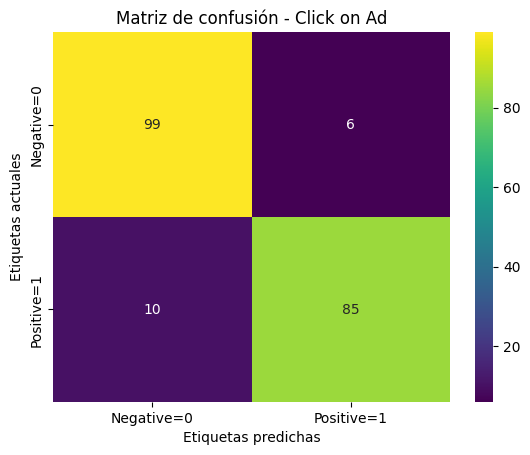

              precision    recall  f1-score   support

           0       0.91      0.94      0.93       105
           1       0.93      0.89      0.91        95

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200

Accuracy: 0.9200


In [199]:
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Matriz de confusión
cm = confusion_matrix(y2_test, y2_pred)
ax = plt.subplot()
sns.heatmap(cm, annot=True, ax = ax, fmt='d', cmap = "viridis")

ax.set_xlabel('Etiquetas predichas')
ax.set_ylabel('Etiquetas actuales')
ax.set_title('Matriz de confusión - Click on Ad')
ax.xaxis.set_ticklabels(['Negative=0', 'Positive=1'])
ax.yaxis.set_ticklabels(['Negative=0', 'Positive=1']);
plt.show();


# Métricas de evaluación
print(classification_report(y2_test, y2_pred)) ## precision,recall,f1-score y support
print(f"Accuracy: {accuracy_score(y2_test, y2_pred):.4f}")


***95% de las predicciones totales fueron correctas***

Clase 0

- Precision = 0.91 → de todos los predichos como "0", el 91% eran realmente 0.
- Recall = 0.94 → de todos los verdaderos "0", el modelo reconoció el 94%.
- F1-score = 0.93 → buen balance entre precisión y recall.

Clase 1

- Precision = 0.93 → de todos los predichos como "1", el 93% eran realmente 1.
- Recall = 0.89 → de todos los verdaderos "1", el modelo reconoció el 89%.
- F1-score = 0.91 → balance también bastante alto.

Probabilidad del verdadero positivo (TPR): [0.         0.01052632 0.68421053 0.68421053 0.74736842 0.74736842
 0.81052632 0.81052632 0.84210526 0.84210526 0.85263158 0.85263158
 0.92631579 0.92631579 0.93684211 0.93684211 0.94736842 0.94736842
 0.95789474 0.95789474 0.96842105 0.96842105 0.97894737 0.97894737
 0.98947368 0.98947368 1.         1.        ]
Probabilidad del falso positivo (FPR): [0.         0.         0.         0.00952381 0.00952381 0.01904762
 0.01904762 0.02857143 0.02857143 0.03809524 0.03809524 0.05714286
 0.05714286 0.06666667 0.06666667 0.07619048 0.07619048 0.0952381
 0.0952381  0.1047619  0.1047619  0.11428571 0.11428571 0.12380952
 0.12380952 0.2        0.2        1.        ]
Área bajo la curva (AUC): 0.9844611528822056


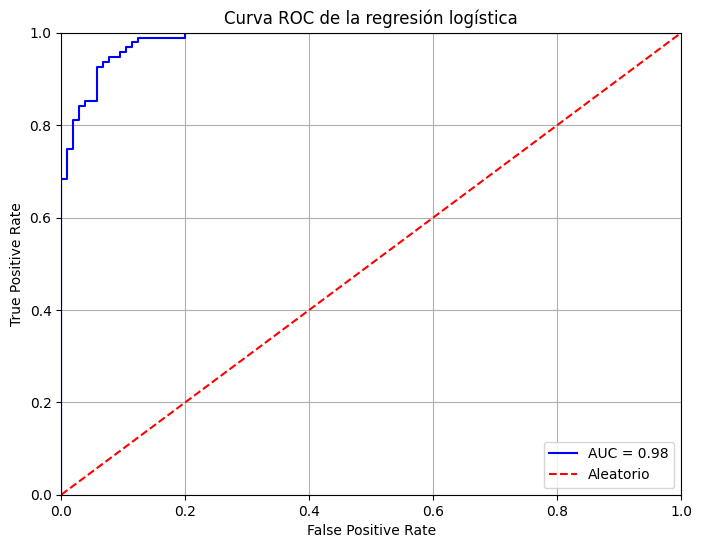

In [200]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Probabilidades predichas por el modelo
probs = log_reg.predict_proba(X2_test)
preds = probs[:, 1]  # probabilidad de la clase positiva

# Calcular curva ROC
fpr, tpr, threshold = roc_curve(y2_test, preds)
roc_auc = auc(fpr, tpr)

# Mostrar métricas en consola
print('Probabilidad del verdadero positivo (TPR):', tpr)
print('Probabilidad del falso positivo (FPR):', fpr)
print('Área bajo la curva (AUC):', roc_auc)

# --- Gráfico ROC ---
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], 'r--', label='Aleatorio')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC de la regresión logística')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

Área bajo la curva (AUC = 0.984):

* 0.5 → sin poder de clasificación.
* 0.7 – 0.8 → aceptable.
* 0.8 – 0.9 → <u>muy bueno.</u>
* 0.9 → excelente

9.  Utilizando los mismos datos separados anteriormente, crear un modelo de clasificación linea usando SVMs. Obtener la matriz de confusión para este modelo; la precision, recall, f1-score, accuracy y curva ROC.